# Part 4. 매출 예측

- Part 3에서는 "하루에 몇 명이 투숙하는가"(수요)를 예측했다. 여기서는 **"하루에 얼마를 버는가"(매출)** 를 예측한다.
- 정의: `매출 = adr(1박 요금) × 숙박일수`, 취소되지 않은 예약만, **투숙 시작일(arrival_date) 기준**으로 집계한다.
- EDA에서 정한 규칙: 가격 분석은 `0 < adr < 1000`만 사용 (Complementary 무료 투숙과 데이터 오류 제외).
- 호텔별(City / Resort)로 따로 예측하고, 시간순 70/15/15 분할을 쓴다.
- 비교할 접근 2가지
  - **A. 직접 예측:** 일별 매출을 바로 타깃으로 LightGBM 학습 (OTB 매출 피처 포함)
  - **B. 분해 예측:** `투숙 수 예측 × 평균 단가(adr) 추정`

In [1]:
import pandas as pd, numpy as np
import lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error

plt.rcParams['font.family'] = 'Malgun Gothic'   # 그래프 한글 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

df = pd.read_csv('hotel_bookings.csv')
df['arrival_date'] = pd.to_datetime(
    df['arrival_date_year'].astype(str) + '-'
    + df['arrival_date_month'] + '-'
    + df['arrival_date_day_of_month'].astype(str),
    format='%Y-%B-%d'
)

In [2]:
# 매출 정의
df['nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['revenue'] = df['adr'] * df['nights']
df['valid_price'] = (df['adr'] > 0) & (df['adr'] < 1000)

print("가격 유효 비율:", df['valid_price'].mean().round(3))
print("숙박일수 0박 예약:", (df['nights'] == 0).sum())
print(df[(df['is_canceled'] == 0) & df['valid_price']].groupby('hotel')['revenue'].describe().round(1))

가격 유효 비율: 0.984
숙박일수 0박 예약: 715
                count   mean    std  min    25%    50%    75%     max
hotel                                                                
City Hotel    45149.0  318.8  219.6  1.0  170.0  270.0  406.1  3910.0
Resort Hotel  28270.0  410.4  432.9  4.0  110.0  256.0  560.0  7590.0


In [3]:
# 호텔별 일별 매출 집계 (취소 제외, 유효 가격만, 투숙 시작일 기준)
START, END = '2015-08-01', '2017-08-31'   # 2015-07 좌측 절단 제거 (Part 3과 동일)

def make_daily_rev(df, hotel):
    h = df[(df['hotel'] == hotel) & (df['is_canceled'] == 0) & df['valid_price']]
    daily = h.groupby('arrival_date').agg(
        revenue=('revenue', 'sum'),
        stays=('revenue', 'size'),
        adr_mean=('adr', 'mean'),
    )
    daily = daily.reindex(pd.date_range(START, END))
    daily['revenue'] = daily['revenue'].fillna(0)
    daily['stays'] = daily['stays'].fillna(0)
    daily['adr_mean'] = daily['adr_mean'].ffill()
    daily.index.name = 'arrival_date'
    return daily.reset_index()

city = make_daily_rev(df, 'City Hotel')
resort = make_daily_rev(df, 'Resort Hotel')

for name, d in [('City', city), ('Resort', resort)]:
    print(f"=== {name} ===  일수 {len(d)}")
    print(d[['revenue', 'stays', 'adr_mean']].describe().round(1))

=== City ===  일수 762
       revenue  stays  adr_mean
count    762.0  762.0     762.0
mean   18785.8   58.7     105.2
std     9985.8   26.2      21.5
min      535.5    3.0      55.8
25%    10983.9   40.0      87.6
50%    18542.9   59.0     103.3
75%    25775.1   74.0     121.9
max    82883.4  202.0     172.6
=== Resort ===  일수 762
       revenue  stays  adr_mean
count    762.0  762.0     762.0
mean   14334.9   35.7      92.0
std    11362.4   15.5      49.4
min      483.8    4.0      33.2
25%     5511.8   26.0      54.9
50%    10994.6   34.0      72.3
75%    19937.2   43.0     118.2
max    64025.9  114.0     239.5


In [4]:
# 월별 매출과 평균 단가 추이 (계절성 확인)
for name, d in [('City', city), ('Resort', resort)]:
    m = d.set_index('arrival_date').resample('MS').agg({'revenue': 'sum', 'stays': 'sum'})
    m['avg_adr'] = (m['revenue'] / m['stays']).round(1)
    print(f"=== {name} 월별 ===")
    print(m.round(0).to_string())

=== City 월별 ===
               revenue  stays  avg_adr
arrival_date                          
2015-08-01    285197.0   1177    242.0
2015-09-01    588545.0   1916    307.0
2015-10-01    521370.0   2000    261.0
2015-11-01    191228.0    904    212.0
2015-12-01    228337.0    909    251.0
2016-01-01    175232.0    895    196.0
2016-02-01    319089.0   1408    227.0
2016-03-01    510578.0   1901    269.0
2016-04-01    579055.0   1987    291.0
2016-05-01    692585.0   2175    318.0
2016-06-01    634282.0   2169    292.0
2016-07-01    744095.0   2051    363.0
2016-08-01    807475.0   2106    383.0
2016-09-01    770776.0   2266    340.0
2016-10-01    719643.0   2218    324.0
2016-11-01    496215.0   1709    290.0
2016-12-01    413103.0   1369    302.0
2017-01-01    352701.0   1300    271.0
2017-02-01    449798.0   1581    284.0
2017-03-01    586024.0   2088    281.0
2017-04-01    790842.0   1969    402.0
2017-05-01    877038.0   2303    381.0
2017-06-01    833587.0   2126    392.0
2017-07-0

## Feature Engineering

Part 3의 피처 설계를 그대로 따르되, **매출 버전 OTB**를 추가한다.
- `otb_N`: 투숙 N일 전 시점에 이미 잡혀 있던 예약 **건수**
- `otb_rev_N`: 같은 시점에 이미 잡혀 있던 예약의 **예상 매출** (adr × 숙박일수)
- OTB는 취소 여부를 알 수 없는 시점의 값이므로 취소 예약도 포함해 집계한다 (Part 3과 동일).
- `otb_3`은 Part 3에서 누수 경계로 제거했으므로 처음부터 쓰지 않는다.

In [5]:
OTB_DAYS = [7, 14, 30, 60, 90]

def add_features(daily, hotel):
    d = daily.copy().sort_values('arrival_date').reset_index(drop=True)

    # 시간 피처
    d['dow'] = d['arrival_date'].dt.dayofweek
    d['month'] = d['arrival_date'].dt.month
    d['is_weekend'] = (d['dow'] >= 5).astype(int)

    # 과거 매출 / 투숙 수 (lag, rolling: shift(1)로 당일 제외)
    for col in ['revenue', 'stays']:
        for lag in [1, 7, 14]:
            d[f'{col}_lag_{lag}'] = d[col].shift(lag)
        d[f'{col}_roll_7'] = d[col].shift(1).rolling(7).mean()
        d[f'{col}_roll_14'] = d[col].shift(1).rolling(14).mean()
    d['adr_roll_14'] = d['adr_mean'].shift(1).rolling(14).mean()

    # OTB (건수 / 매출)
    hv = df[(df['hotel'] == hotel) & df['valid_price']]
    for n in OTB_DAYS:
        sub = hv[hv['lead_time'] >= n].groupby('arrival_date')
        d[f'otb_{n}'] = d['arrival_date'].map(sub.size()).fillna(0)
        d[f'otb_rev_{n}'] = d['arrival_date'].map(sub['revenue'].sum()).fillna(0)
    d['otb_rev_pace'] = d['otb_rev_7'] - d['otb_rev_30']

    return d.dropna().reset_index(drop=True)

city_fe = add_features(city, 'City Hotel')
resort_fe = add_features(resort, 'Resort Hotel')
print("City:", city_fe.shape, "| Resort:", resort_fe.shape)

def split_time(d, train_ratio=0.7, valid_ratio=0.15):
    n = len(d)
    t1, t2 = int(n * train_ratio), int(n * (train_ratio + valid_ratio))
    return d.iloc[:t1], d.iloc[t1:t2], d.iloc[t2:]

for name, d in [('City', city_fe), ('Resort', resort_fe)]:
    tr, va, te = split_time(d)
    print(f"{name}: train {len(tr)} | valid {len(va)} | test {len(te)} | test {te['arrival_date'].min().date()} ~ {te['arrival_date'].max().date()}")

City: (748, 29) | Resort: (748, 29)
City: train 523 | valid 112 | test 113 | test 2017-05-11 ~ 2017-08-31
Resort: train 523 | valid 112 | test 113 | test 2017-05-11 ~ 2017-08-31


In [6]:
# 평가 지표: MAPE는 매출이 작은 날에 크게 튀므로 WAPE(가중 오차율)를 함께 본다
def report(y, pred, label):
    mae = mean_absolute_error(y, pred)
    mape = mean_absolute_percentage_error(y, pred)
    wape = np.abs(y - pred).sum() / np.abs(y).sum()
    print(f"{label:<28} MAE {mae:>9,.0f} | MAPE {mape:.3f} | WAPE {wape:.3f}")
    return dict(label=label, MAE=mae, MAPE=mape, WAPE=wape)

params_reg = {'objective': 'regression', 'metric': 'mae', 'learning_rate': 0.05,
              'num_leaves': 31, 'verbose': -1, 'seed': 42}

def fit_lgb(tr, va, feats, target):
    dtr = lgb.Dataset(tr[feats], label=tr[target])
    dva = lgb.Dataset(va[feats], label=va[target], reference=dtr)
    return lgb.train(params_reg, dtr, num_boost_round=1000, valid_sets=[dva],
                     callbacks=[lgb.early_stopping(50), lgb.log_evaluation(0)])

## A. 직접 예측: 일별 매출을 바로 예측

단계별로 피처를 추가하며 어떤 정보가 매출 예측에 기여하는지 본다.
1. 베이스라인: 지난주 같은 요일 매출 (`revenue_lag_7`)
2. 시간 + lag/rolling
3. + OTB 건수
4. + OTB 매출 (+ pace)

In [7]:
feat_base = ['dow', 'month', 'is_weekend',
             'revenue_lag_1', 'revenue_lag_7', 'revenue_lag_14',
             'revenue_roll_7', 'revenue_roll_14']
feat_otb_cnt = feat_base + [f'otb_{n}' for n in OTB_DAYS]
feat_otb_rev = feat_otb_cnt + [f'otb_rev_{n}' for n in OTB_DAYS] + ['otb_rev_pace']

results, preds, models = [], {}, {}

for name, d in [('City', city_fe), ('Resort', resort_fe)]:
    tr, va, te = split_time(d)
    y = te['revenue']
    print(f"\n===== {name} (직접 예측) =====")
    r = report(y, te['revenue_lag_7'], '베이스라인 (지난주)')
    results.append({'hotel': name, **r})
    for label, feats in [('LGBM 시간+lag', feat_base),
                         ('LGBM + OTB 건수', feat_otb_cnt),
                         ('LGBM + OTB 매출 (최종 A)', feat_otb_rev)]:
        m = fit_lgb(tr, va, feats, 'revenue')
        p = m.predict(te[feats])
        r = report(y, p, label)
        results.append({'hotel': name, **r})
    preds[(name, 'A')] = p
    models[name] = (m, feat_otb_rev)


===== City (직접 예측) =====
베이스라인 (지난주)                  MAE     6,744 | MAPE 0.249 | WAPE 0.239
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[78]	valid_0's l1: 5031.86
LGBM 시간+lag                  MAE     5,840 | MAPE 0.195 | WAPE 0.207
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[65]	valid_0's l1: 3710.58
LGBM + OTB 건수                MAE     4,589 | MAPE 0.155 | WAPE 0.163


Training until validation scores don't improve for 50 rounds


Early stopping, best iteration is:
[44]	valid_0's l1: 3433.88
LGBM + OTB 매출 (최종 A)         MAE     3,472 | MAPE 0.123 | WAPE 0.123

===== Resort (직접 예측) =====
베이스라인 (지난주)                  MAE     6,802 | MAPE 0.296 | WAPE 0.260
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[31]	valid_0's l1: 4467.06
LGBM 시간+lag                  MAE     6,345 | MAPE 0.264 | WAPE 0.243
Training until validation scores don't improve for 50 rounds


Early stopping, best iteration is:
[62]	valid_0's l1: 2912.13
LGBM + OTB 건수                MAE     4,600 | MAPE 0.203 | WAPE 0.176
Training until validation scores don't improve for 50 rounds


Early stopping, best iteration is:
[136]	valid_0's l1: 1900.44
LGBM + OTB 매출 (최종 A)         MAE     3,951 | MAPE 0.179 | WAPE 0.151


In [8]:
# 피처 중요도 (최종 A)
for name in ['City', 'Resort']:
    m, feats = models[name]
    imp = pd.DataFrame({'feature': feats, 'gain': m.feature_importance(importance_type='gain')})
    imp['gain_pct'] = (imp['gain'] / imp['gain'].sum() * 100).round(1)
    print(f"\n=== {name} 피처 중요도 (상위 8) ===")
    print(imp.sort_values('gain', ascending=False).head(8).to_string(index=False))


=== City 피처 중요도 (상위 8) ===
       feature         gain  gain_pct
     otb_rev_7 3.477824e+11      81.3
 revenue_lag_7 1.208841e+10       2.8
    otb_rev_14 1.126063e+10       2.6
  otb_rev_pace 9.512043e+09       2.2
    otb_rev_60 9.351347e+09       2.2
 revenue_lag_1 6.586685e+09       1.5
    otb_rev_30 5.336659e+09       1.2
revenue_roll_7 3.841749e+09       0.9

=== Resort 피처 중요도 (상위 8) ===
       feature         gain  gain_pct
     otb_rev_7 2.308411e+11      42.1
    otb_rev_14 2.225450e+11      40.6
    otb_rev_30 5.917798e+10      10.8
    otb_rev_60 6.955261e+09       1.3
 revenue_lag_7 6.584516e+09       1.2
revenue_lag_14 4.977584e+09       0.9
        otb_30 2.301272e+09       0.4
    otb_rev_90 1.940666e+09       0.4


## B. 분해 예측: 투숙 수 × 평균 단가

`매출 = 투숙 수 × 평균 단가(객실당 1박 요금 × 평균 숙박일수)`로 분해한다.
- 투숙 수: Part 3 방식(OTB 건수 포함)의 LightGBM으로 예측
- 단가: 직전 14일 평균 adr(`adr_roll_14`)과 지난 14일 평균 숙박일수로 추정
- 매출 효율(= 매출 / 투숙 수)의 최근 14일 평균을 단가로 사용한다.

In [9]:
for name, d in [('City', city_fe), ('Resort', resort_fe)]:
    tr, va, te = split_time(d)
    y = te['revenue']

    # 1) 투숙 수 모델 (Part 3 최종과 같은 구성, otb_rev 제외)
    feat_stays = ['dow', 'month', 'is_weekend', 'stays_lag_1', 'stays_lag_7', 'stays_lag_14',
                  'stays_roll_7', 'stays_roll_14'] + [f'otb_{n}' for n in OTB_DAYS]
    m_s = fit_lgb(tr, va, feat_stays, 'stays')
    stays_pred = m_s.predict(te[feat_stays])

    # 2) 평균 매출/투숙 (단가): 직전 14일의 revenue_roll_14 / stays_roll_14
    rev_per_stay = (te['revenue_roll_14'] / te['stays_roll_14'].replace(0, np.nan)).ffill()

    pred_b = stays_pred * rev_per_stay.values
    preds[(name, 'B')] = pred_b
    print(f"\n===== {name} (분해 예측) =====")
    print(f"투숙 수 MAPE: {mean_absolute_percentage_error(te['stays'], stays_pred):.3f}")
    r = report(y, pred_b, '분해 B (투숙수 × 단가)')
    results.append({'hotel': name, **r})

    # 3) A와 B의 단순 평균 (앙상블)
    pred_ens = (preds[(name, 'A')] + pred_b) / 2
    preds[(name, 'ENS')] = pred_ens
    r = report(y, pred_ens, '앙상블 (A+B 평균)')
    results.append({'hotel': name, **r})

Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[29]	valid_0's l1: 11.4322

===== City (분해 예측) =====
투숙 수 MAPE: 0.127
분해 B (투숙수 × 단가)              MAE     4,383 | MAPE 0.154 | WAPE 0.156
앙상블 (A+B 평균)                 MAE     3,459 | MAPE 0.122 | WAPE 0.123
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[44]	valid_0's l1: 6.70206

===== Resort (분해 예측) =====
투숙 수 MAPE: 0.184
분해 B (투숙수 × 단가)              MAE     4,890 | MAPE 0.216 | WAPE 0.187
앙상블 (A+B 평균)                 MAE     3,924 | MAPE 0.179 | WAPE 0.150


In [10]:
summary = pd.DataFrame(results).set_index(['hotel', 'label']).round(3)
print(summary.to_string())
summary.to_csv('revenue_forecast_results.csv', encoding='utf-8-sig')

                                  MAE   MAPE   WAPE
hotel  label                                       
City   베이스라인 (지난주)           6744.364  0.249  0.239
       LGBM 시간+lag           5840.456  0.195  0.207
       LGBM + OTB 건수         4589.322  0.155  0.163
       LGBM + OTB 매출 (최종 A)  3472.330  0.123  0.123
Resort 베이스라인 (지난주)           6801.512  0.296  0.260
       LGBM 시간+lag           6345.056  0.264  0.243
       LGBM + OTB 건수         4599.604  0.203  0.176
       LGBM + OTB 매출 (최종 A)  3951.435  0.179  0.151
City   분해 B (투숙수 × 단가)       4383.456  0.154  0.156
       앙상블 (A+B 평균)          3459.292  0.122  0.123
Resort 분해 B (투숙수 × 단가)       4890.438  0.216  0.187
       앙상블 (A+B 평균)          3923.533  0.179  0.150


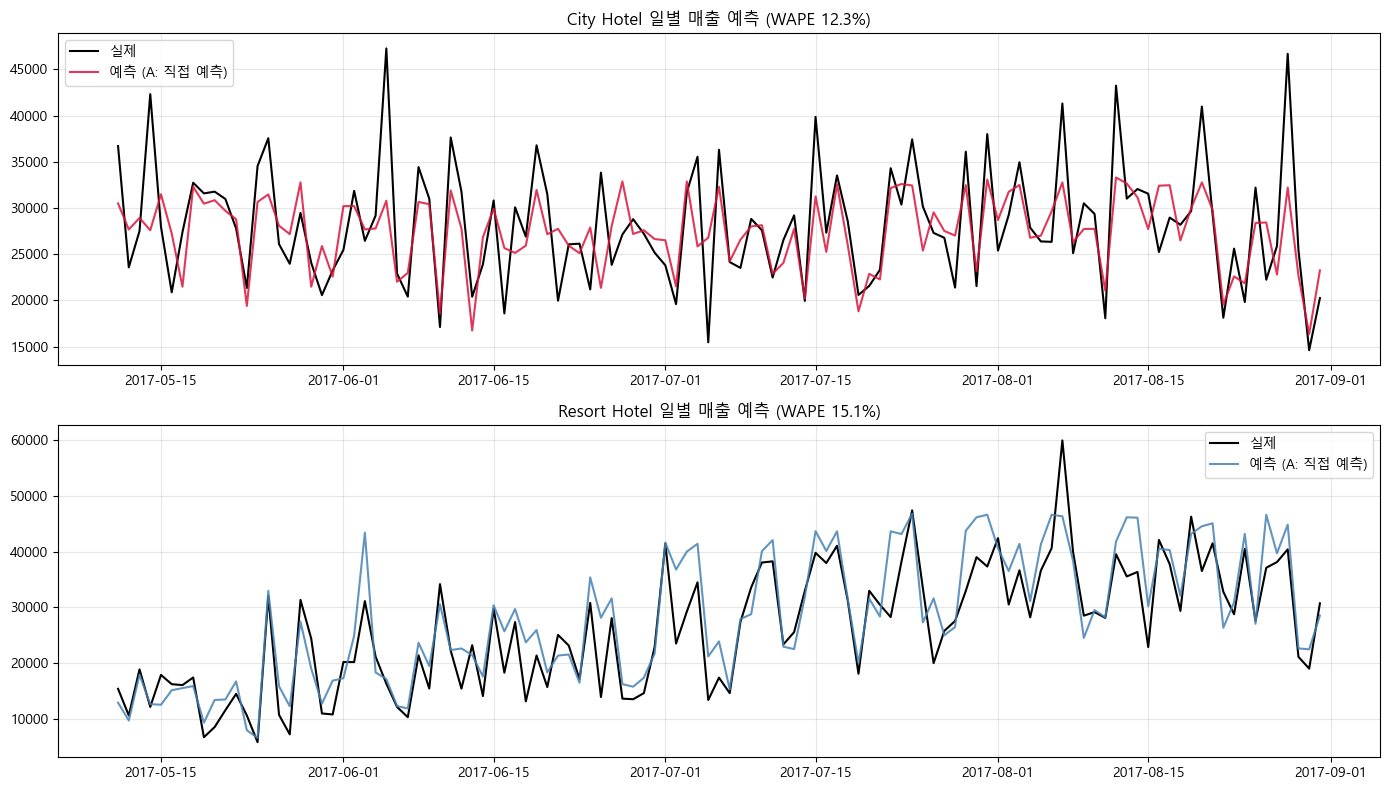

In [11]:
# 시각화: 실제 vs 예측 (테스트 구간)
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
for ax, (name, d), color in zip(axes, [('City', city_fe), ('Resort', resort_fe)], ['crimson', 'steelblue']):
    _, _, te = split_time(d)
    best = preds[(name, 'A')]
    wape = np.abs(te['revenue'].values - best).sum() / te['revenue'].sum()
    ax.plot(te['arrival_date'], te['revenue'].values, label='실제', color='black', linewidth=1.5)
    ax.plot(te['arrival_date'], best, label='예측 (A: 직접 예측)', color=color, linewidth=1.5, alpha=0.85)
    ax.set_title(f'{name} Hotel 일별 매출 예측 (WAPE {wape:.1%})')
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('revenue_forecast.png', dpi=120, bbox_inches='tight')
plt.show()

## 결과 정리 (실행 후 채우기)

| 호텔 | 베이스라인 WAPE | 직접 예측 A | 분해 B | 앙상블 |
|---|---|---|---|---|
| City | | | | |
| Resort | | | | |

- 해석: